# Decision Tree Tutorial

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.linear_model import LogisticRegression

sns.set(style="whitegrid")

## Load and Explore the Iris Dataset

In [2]:
iris = load_iris()
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['target'] = iris.target
df['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


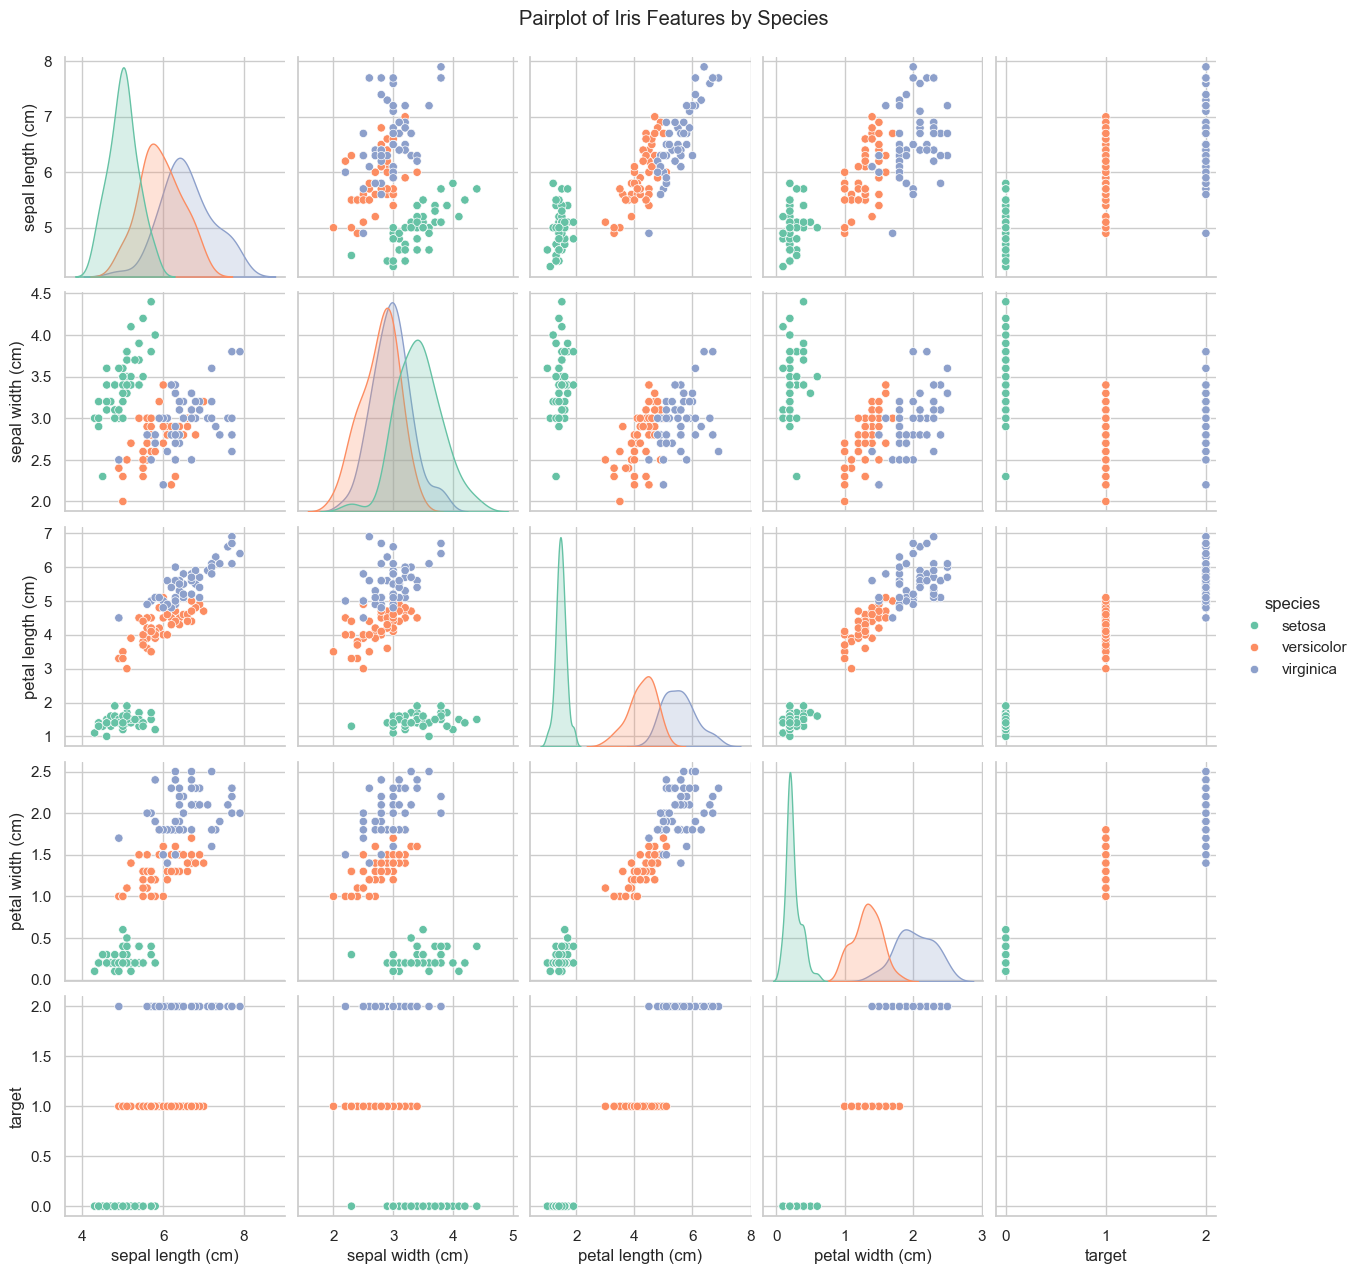

In [3]:
sns.pairplot(df, hue='species', palette='Set2')
plt.suptitle("Pairplot of Iris Features by Species", y=1.02)
plt.show()

In [9]:
X = df[iris.feature_names]
y = df['species']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

## Train a Decision Tree

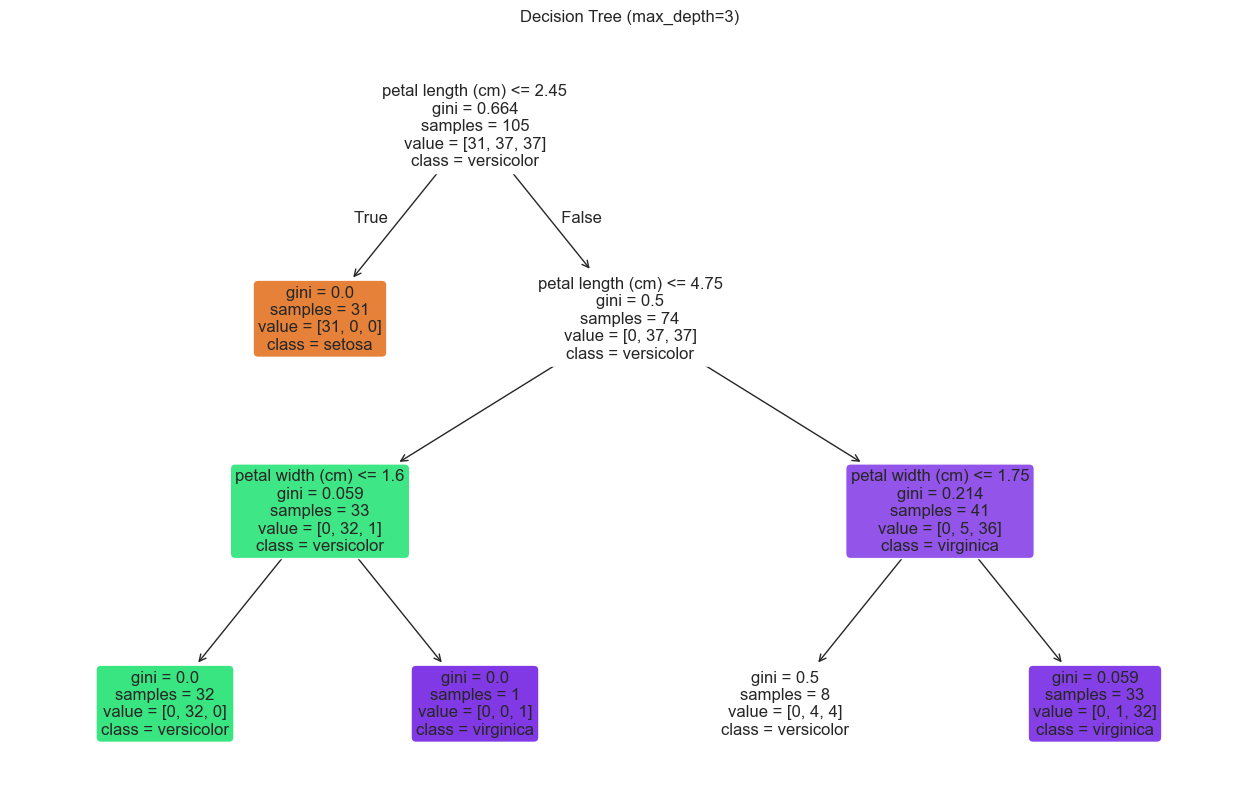

In [10]:
clf = DecisionTreeClassifier(random_state=42, max_depth=3)
clf.fit(X_train, y_train)

plt.figure(figsize=(16, 10))
plot_tree(clf, feature_names=iris.feature_names, class_names=iris.target_names,
          filled=True, rounded=True, fontsize=12)
plt.title("Decision Tree (max_depth=3)")
plt.show()

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



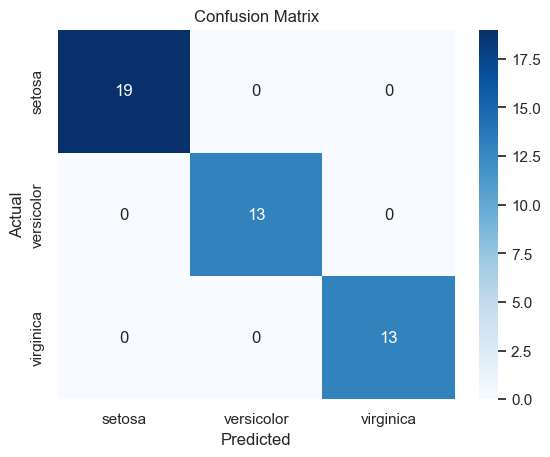

In [11]:
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, cmap='Blues',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

## Overfitting vs Underfitting

In [12]:
clf_deep = DecisionTreeClassifier(random_state=0)
clf_deep.fit(X_train, y_train)

print("Train Accuracy (deep tree):", clf_deep.score(X_train, y_train))
print("Test Accuracy (deep tree):", clf_deep.score(X_test, y_test))

Train Accuracy (deep tree): 1.0
Test Accuracy (deep tree): 1.0


## Feature Importance

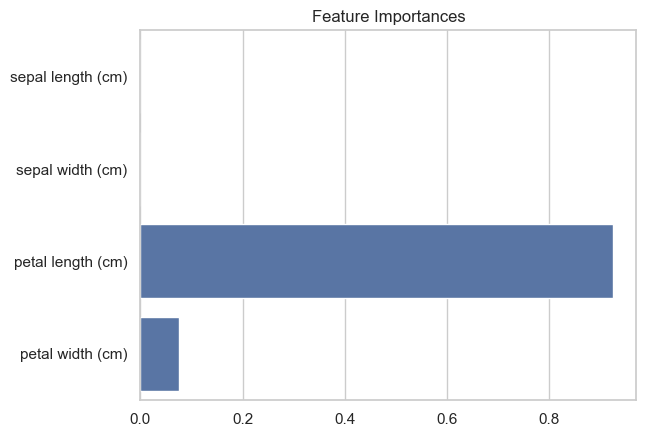

In [13]:
importances = clf.feature_importances_
sns.barplot(x=importances, y=iris.feature_names)
plt.title("Feature Importances")
plt.show()

## Hyperparameter Tuning

In [14]:
param_grid = {
    'max_depth': [2, 3, 4, 5],
    'min_samples_split': [2, 4, 6]
}
grid = GridSearchCV(DecisionTreeClassifier(), param_grid, cv=5)
grid.fit(X_train, y_train)
print("Best Parameters:", grid.best_params_)
print("Best Score:", grid.best_score_)

Best Parameters: {'max_depth': 4, 'min_samples_split': 6}
Best Score: 0.9428571428571428


## Compare with Logistic Regression

In [15]:
logreg = LogisticRegression(max_iter=200)
logreg.fit(X_train, y_train)
logreg_preds = logreg.predict(X_test)

print("Logistic Regression Accuracy:", accuracy_score(y_test, logreg_preds))

Logistic Regression Accuracy: 1.0
